# Add processed signals to a raw-only NWB file

An NWB file converted with `hadjas-2025 convert <data folder> <output folder> --processed none` holds the raw photodetector signal of each session (the TDT Fi1r store) but no processed signals. This notebook computes the processed signals from that raw signal and adds them to the file:

- the demodulated 465 nm (calcium) and 405 nm (isosbestic control) signals, at the rate of the raw signal;
- the same two signals resampled to 100 Hz;
- dF/F, in percent, against a bi-exponential fit of the isosbestic signal scaled to the calcium signal.

The steps follow the lab's MATLAB analysis code and are done separately for each TDT block of the session. Demodulation and resampling give the lab's values. dF/F can differ where the bi-exponential fit differs from MATLAB's; the section "Differences from the lab's MATLAB code" of the `hadjas_2025.processing` module describes where and why. The descriptions of the added series say that they were recomputed by this package, with its version.

The conversion does the same when `data_streams.processed` is `recomputed` in the session config (or with `--processed recomputed`).

## 1. Choose the file

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO

from hnasko_lab_to_nwb.hadjas_2025.convert_session import get_led_modulation, load_cohort_metadata
from hnasko_lab_to_nwb.hadjas_2025.recompute import add_recomputed_processed_series

# A raw-only NWB file, and the cohort of its subject (a key of "cohorts" in metadata/session_config.yaml)
raw_nwbfile_path = Path("nwb_files/sub-C4561_ses-varying_durations.nwb")
recording_type = "SN pan GABA recordings"

# The processed series are added to a copy, so that the raw-only file stays as it is
nwbfile_path = raw_nwbfile_path.with_name(raw_nwbfile_path.stem + "_recomputed.nwb")
shutil.copy(raw_nwbfile_path, nwbfile_path)
print(f"Processed series will be added to {nwbfile_path}")

Processed series will be added to nwb_files\sub-C4561_ses-varying_durations_recomputed.nwb


## 2. Look at the raw signal

The raw series is in `nwbfile.acquisition`. A session of several TDT blocks (varying frequencies) is written as one series with timestamps; the gaps between blocks are where it is split again before processing. The modulation frequencies of the two LEDs depend on the recording date (`led_modulation` in the session config).

In [2]:
with NWBHDF5IO(raw_nwbfile_path, "r") as io:
    nwbfile = io.read()
    raw_series = next(iter(nwbfile.acquisition.values()))
    print(f"Raw series: {raw_series.name}, {raw_series.data.shape[0]} samples")
    print(f"Session start: {nwbfile.session_start_time}")
    print(f"Processing modules in the file: {list(nwbfile.processing)}")
    led_modulation = get_led_modulation(nwbfile.session_start_time)
print(f"LED modulation: {led_modulation}")

Raw series: raw_signal_SNr, 1580544 samples
Session start: 2024-01-18 10:24:58.999999-08:00
Processing modules in the file: []


LED modulation: {'calcium_signal_in_hz': 330.0, 'isosbestic_control_in_hz': 210.0}


## 3. Add the processed series

The cohort's metadata file gives the names, units and FiberPhotometryTable rows of the series, as for the conversion. The raw series has the metadata key `Fi1r_<recording site>`; the processed series of that site have the keys `Gc_raw_<site>`, `af_raw_<site>`, `Gc_<site>`, `af_<site>` and `dF_<site>`. The file is opened in append mode and the series are written to its `ophys` processing module.

In [3]:
metadata = load_cohort_metadata(recording_type)
with NWBHDF5IO(nwbfile_path, "a") as io:
    nwbfile = io.read()
    raw_series_name = next(iter(nwbfile.acquisition))
    raw_metadata_key = next(
        key
        for key, series_metadata in metadata["FiberPhotometry"].items()
        if key.startswith("Fi1r_") and series_metadata["name"] == raw_series_name
    )
    add_recomputed_processed_series(
        nwbfile=nwbfile, metadata=metadata, raw_metadata_key=raw_metadata_key, led_modulation=led_modulation
    )
    io.write(nwbfile)

with NWBHDF5IO(nwbfile_path, "r") as io:
    ophys = io.read().processing["ophys"]
    for name, series in ophys.data_interfaces.items():
        print(f"{name}: {series.data.shape[0]} samples, {series.unit}")
    print()
    print(ophys[f"deltaF_over_F_{raw_metadata_key.removeprefix('Fi1r_')}"].description)

deltaF_over_F_SNr: 25895 samples, percent
demodulated_calcium_signal_SNr: 1580544 samples, a.u.
demodulated_isosbestic_control_SNr: 1580544 samples, a.u.
downsampled_calcium_signal_SNr: 25895 samples, a.u.
downsampled_isosbestic_control_SNr: 25895 samples, a.u.

dF/F of the GCaMP6f signal in the substantia nigra pars reticulata (SNr), in percent, recomputed from the raw signal with hadjas_2025.processing of hnasko-lab-to-nwb 0.0.1, a Python port of the lab's MATLAB code (its bi-exponential fit of the isosbestic signal can differ from the lab's; see the processing module). A biexponential curve was fit to the 100 Hz isosbestic signal and scaled to the 100 Hz 465 nm signal by robust linear regression; dF/F = 100 * (465 nm signal - scaled fit) / scaled fit.


## 4. Plot the recomputed signals

The 100 Hz calcium and isosbestic signals, and dF/F with the optogenetic stimulation trains shaded.

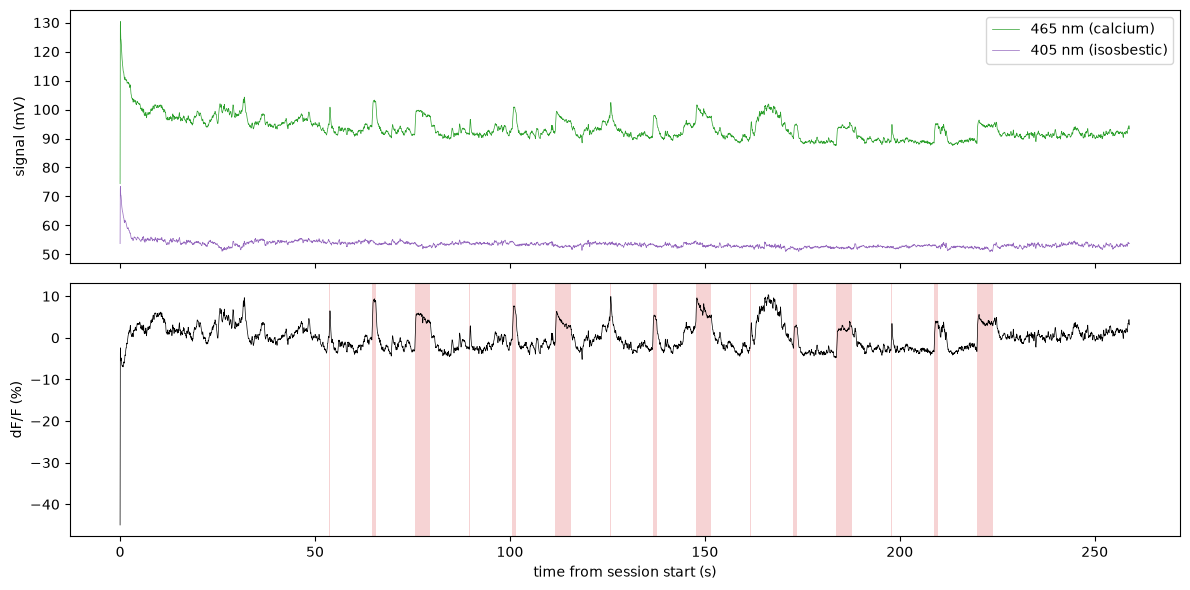

In [4]:
site = raw_metadata_key.removeprefix("Fi1r_")
with NWBHDF5IO(nwbfile_path, "r") as io:
    nwbfile = io.read()
    ophys = nwbfile.processing["ophys"]
    calcium = ophys[f"downsampled_calcium_signal_{site}"]
    isosbestic = ophys[f"downsampled_isosbestic_control_{site}"]
    dff = ophys[f"deltaF_over_F_{site}"]
    epochs = nwbfile.intervals["optogenetic_epochs_table"].to_dataframe()

    figure, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    axes[0].plot(calcium.get_timestamps(), 1000 * calcium.data[:], lw=0.5, color="tab:green", label="465 nm (calcium)")
    axes[0].plot(isosbestic.get_timestamps(), 1000 * isosbestic.data[:], lw=0.5, color="tab:purple", label="405 nm (isosbestic)")
    axes[0].set_ylabel("signal (mV)")
    axes[0].legend(loc="upper right")
    axes[1].plot(dff.get_timestamps(), dff.data[:], lw=0.5, color="black")
    for start_time, stop_time in zip(epochs["start_time"], epochs["stop_time"]):
        axes[1].axvspan(start_time, stop_time, color="tab:red", alpha=0.2, lw=0)
    axes[1].set_ylabel("dF/F (%)")
    axes[1].set_xlabel("time from session start (s)")
    figure.tight_layout()
    plt.show()